# LLM-Assisted PID Control of a Water Tank

**Reproduction of:** *"An experiment of using a large language model to control a water tank system"* (Wen et al., 2026)

## The big picture

A water tank must be filled to a target level (10 m). A classic **PID controller** adjusts the pump, but its three gains (Kp, Ki, Kd) are fixed and tedious to tune by hand.

**Our twist (vs. the paper):** an LLM (**SiliconFlow → `deepseek-ai/DeepSeek-V4.1-Flash`, driven by the OpenAI Agents SDK**) re-tunes those gains *while the tank is running*, and we **pause the simulation** until the LLM answers. The paper instead assumed a fixed 0.3 s latency and let the loop keep running.


## 1. Setup — libraries, provider and API key

We need a small set of libraries:
- `numpy` — math for the tank physics
- `matplotlib` — plots
- `openai` + `agents` — the **OpenAI Python client** and the **OpenAI Agents SDK**; we point the client at **SiliconFlow** (an OpenAI-compatible endpoint) and let the Agents SDK drive the model
- `nest_asyncio` — lets `Runner.run_sync()` work inside Jupyter's already-running event loop
- `python-dotenv` — reads the API key from the `.env` file

In [1]:
import os, time, re
import numpy as np
import matplotlib.pyplot as plt
from dotenv import load_dotenv
import nest_asyncio

# --- Compatibility shim ---------------------------------------------------
# openai-agents 0.4.2 builds its Usage() with InputTokensDetails(cached_tokens=0),
# but openai >= 2.2 made `cache_write_tokens` a required field. Give it a default.
from openai.types.responses.response_usage import InputTokensDetails
_f = InputTokensDetails.model_fields["cache_write_tokens"]
_f.default = 0
_f.default_factory = None
InputTokensDetails.model_rebuild(force=True)
# --------------------------------------------------------------------------

from openai import AsyncOpenAI
from agents import (
    Agent, Runner, RunConfig, OpenAIProvider, ModelSettings,
    set_tracing_disabled,
    set_default_openai_client,
    set_default_openai_api,
)

nest_asyncio.apply()          # allow Runner.run_sync() inside Jupyter's running event loop
load_dotenv()

API_KEY  = os.getenv("SILICON_FLOW_API_KEY")
BASE_URL = "https://api.siliconflow.com/v1"     # OpenAI-compatible endpoint
MODEL    = "deepseek-ai/DeepSeek-V4.1-Flash"

client = AsyncOpenAI(base_url=BASE_URL, api_key=API_KEY)

# An explicit provider pins the model to SiliconFlow (Chat Completions API).
# This also stops the SDK's MultiProvider from mis-reading the "deepseek-ai/" in
# the model name as a provider prefix.
provider = OpenAIProvider(openai_client=client, use_responses=False)
run_cfg  = RunConfig(model_provider=provider, tracing_disabled=True)

# Same defaults, for convenience if an Agent is run without an explicit run_config
set_default_openai_client(client, use_for_tracing=False)
set_default_openai_api("chat_completions")
set_tracing_disabled(True)

print(f"  SiliconFlow + OpenAI Agents SDK ready  |  model={MODEL}")

  SiliconFlow + OpenAI Agents SDK ready  |  model=deepseek-ai/DeepSeek-V4.1-Flash


## 2. The water tank (the "plant")

From the paper, Eq. (1): the tank level $H$ changes according to

$$A\,\frac{dH}{dt} = b\,V - a\sqrt{H}$$

- $V$ = pump voltage (what the controller sets, 0–1)
- $H$ = water height (what we measure)
- $A, a, b$ = tank constants

We simulate it with tiny time steps (0.1 s), exactly like the paper.

In [2]:
# Tank constants.
# These are chosen so the 10 m setpoint is actually REACHABLE and the tank
# settles comfortably inside our 100 s run:
#     steady state:  b*V = a*sqrt(H)   ->   H_ss(V) = (b*V/a)^2 = 25*V^2
#     at full pump (V=1) the ceiling is 25 m, and holding 10 m needs only
#     V = 0.63, so the controller has room to work in both directions.
A = 1.5    # tank cross-sectional area (m^2)
a = 0.5    # outflow constant  -> drain speed is proportional to sqrt(H)
b = 2.5    # pump constant     -> fill speed is proportional to V


def tank_step(H, V, dt=0.1):
    """One small step of tank physics: returns the new water height."""
    dH = (b * V - a * np.sqrt(max(H, 0.0))) / A
    return max(H + dH * dt, 0.0)   # level can't go below 0


# Sanity check: at full pump the tank climbs towards its (b/a)^2 = 25 m ceiling
H = 0.0
for _ in range(600):
    H = tank_step(H, V=1.0)
print(f"Tank after 60 s at full pump: H = {H:.2f} m  (ceiling {(b / a) ** 2:.0f} m \u2714)")
print(f"Steady-state level the pump can hold at half throttle: {(b * 0.5 / a) ** 2:.2f} m")


Tank after 60 s at full pump: H = 22.46 m  (ceiling 25 m ✔)
Steady-state level the pump can hold at half throttle: 6.25 m


## 3. The PID controller (the classic part)

The PID law, Eq. (2) of the paper:

$$u(t) = K_p\,e(t) + K_i\!\int e\,dt + K_d\,\frac{de}{dt}$$

where $e(t) = H_{ref} - H$ is the error (how far we are from the target).

- **Kp** reacts to *how far* we are
- **Ki** remembers *how long* we've been off
- **Kd** reacts to *how fast* the error is changing

The LLM's only job: suggest better values for these 3 numbers.

In [11]:
# The ONE fixed set of gains used throughout -- the hand-tuned, non-adaptive
# reference. The fixed-gain case runs with exactly this, and the LLM-PID case
# starts from this same set and only ever *perturbs* it.
FIXED_GAINS = (0.5, 0.02, 0.0)        # (Kp, Ki, Kd)


class PID:
    """PID controller. The LLM is allowed to change kp, ki, kd.

    Two practical details beyond the textbook law -- without them the pump
    command chatters (a huge TVu) and the gains become meaningless:
      * the derivative term is low-pass filtered (a raw delta-e/dt is pure noise)
      * anti-windup: while the pump is saturated we stop growing the integral
    """

    def __init__(self, kp=None, ki=None, kd=None, tau_d=2.0, u_min=0.0, u_max=1.0):
        kp = FIXED_GAINS[0] if kp is None else kp
        ki = FIXED_GAINS[1] if ki is None else ki
        kd = FIXED_GAINS[2] if kd is None else kd
        self.kp, self.ki, self.kd = kp, ki, kd
        self.tau_d = tau_d                    # derivative filter time constant (s)
        self.u_min, self.u_max = u_min, u_max
        self.integral = 0.0
        self.prev_err = None
        self.d_filt = 0.0

    def update(self, error, dt=0.1):
        self.integral += error * dt

        raw = 0.0 if self.prev_err is None else (error - self.prev_err) / dt
        alpha = dt / (self.tau_d + dt)        # 1st-order low-pass on the derivative
        self.d_filt += alpha * (raw - self.d_filt)
        self.prev_err = error

        u = self.kp * error + self.ki * self.integral + self.kd * self.d_filt
        u_sat = float(np.clip(u, self.u_min, self.u_max))

        if abs(u - u_sat) > 1e-12:            # saturated -> don't wind up
            self.integral -= error * dt
            u_sat = float(np.clip(self.kp * error + self.ki * self.integral
                                  + self.kd * self.d_filt, self.u_min, self.u_max))
        return u_sat


print(f"Fixed gains (reference case): Kp={FIXED_GAINS[0]}, "
      f"Ki={FIXED_GAINS[1]}, Kd={FIXED_GAINS[2]}")


Fixed gains (reference case): Kp=0.5, Ki=0.02, Kd=0.0


## 4. The LLM tuner (the AI part) — SiliconFlow + OpenAI Agents SDK

Every few seconds we send the LLM the state of the loop and ask for new PID gains.

**The LLM perturbs one fixed gain set; it does not search for an optimum.** There is a single, hand-picked reference — `FIXED_GAINS = (Kp=0.50, Ki=0.020, Kd=0.000)`. The fixed-gain case runs with those numbers forever. The LLM-PID case starts from the same numbers and is told, in the prompt, that its job is **not to replace them but to nudge them in small steps** — at most **±30 % per gain per turn**, and it must **stop changing them once the response is good**.

The agent is given the same feedback a human tuner would use — the current error, the current gains, *the reference gains*, how high the level has peaked, how much error has accumulated (IAE), and the **measured rate of rise** (m/s since the last call). The rate matters: with only the raw error, a naive agent just winds the gains up and makes the loop *worse*. Keying the decision on a *measured trend* rather than on the size of the error is what keeps it from over-tuning.

SiliconFlow serves an **OpenAI-compatible** `/chat/completions` API, and we drive it with the **OpenAI Agents SDK**: one `Agent` whose `instructions` are the tuning prompt, invoked with `Runner.run_sync(...)` (which blocks until the reply is ready). We disable the SDK's tracing because we are using a third-party provider, and we pass `extra_body={"enable_thinking": False}` — `DeepSeek-V4.1-Flash` otherwise spends 17–19 s emitting reasoning tokens and returns an empty `content`.

Key difference from the paper: the paper's Simulink loop *kept running* during the ~0.3 s LLM call and just assumed the answer arrives in time. Our version **pauses the simulation clock** until the LLM actually replies, so the LLM latency is *measured*, not assumed.

In [12]:
# The "AI engineer": one system prompt that tells the LLM how to tune.
#
# The framing matters. The LLM is NOT asked to design a controller -- a fixed
# set of gains already exists and is the reference case. It is asked to
# PERTURB that set, in small steps, in the direction that improves the
# response, and to stop once the response is good. Two lessons went into this
# wording: with only the raw error a naive agent just winds the gains up and
# makes the loop WORSE; but with only "is the error shrinking?" it never acts,
# because the error also shrinks during a hopelessly slow fill. So the rule
# keys off the measured RATE, and every move is bounded to a small nudge.
TUNER_INSTRUCTIONS = """You are a PID tuning expert for a water tank level controller.

Plant: the level H follows  A dH/dt = b V - a sqrt(H), where V in [0,1] is the
pump command. The setpoint is 10.0 m and the tank starts empty.

A hand-chosen FIXED set of gains is used as the non-adaptive reference case:
    Kp=0.50, Ki=0.020, Kd=0.000
Your job is NOT to replace it. Your job is to PERTURB that set in small steps:
nudge the gains in whichever direction improves the response, and STOP
changing them once the response is good.

Each turn you are told: the elapsed time, the current error (setpoint - level),
the current gains, the measured rate of change of the level (m/s), the highest
level so far, and the accumulated |error| (IAE).

Rules:
  * Move each gain by at most +/-30% of its CURRENT value in one turn. Small
    nudges only -- never double a gain.
  * Level well below setpoint (error > 0.2 m) and rising slower than 0.20 m/s
    (or flat, or falling) -> the loop is sluggish. Raise Ki by ~30% and raise
    Kp by up to ~20%. A large error alone is NOT a reason to raise the gains.
  * Level above setpoint (error < -0.2 m), or oscillating around it -> overshoot.
    Lower Ki by ~30% and/or lower Kp, or add a small Kd.
  * Within 0.2 m of setpoint and stable -> STOP. Repeat the current gains.
  * Keep the gains inside 0 <= Kp <= 1.5, 0 <= Ki <= 0.20, 0 <= Kd <= 0.20.
    These bounds are deliberately tight because you are perturbing the fixed
    set, not searching for a new controller.

Reply with ONLY one line, exactly this format:
Kp=<number>, Ki=<number>, Kd=<number>
No explanation, no preamble, just the line."""

# The Agents-SDK "agent": the LLM that plays the PID-tuning engineer.
# DeepSeek-V4.1-Flash *reasons* by default (~17 s/call); enable_thinking=False
# makes it answer directly (~2-3 s/call) -- essential here, because the closed
# loop calls it many times. temperature=0 keeps repeat runs reproducible.
pid_tuner_agent = Agent(
    name="PID Tuner",
    model=MODEL,                      # deepseek-ai/DeepSeek-V4.1-Flash on SiliconFlow
    instructions=TUNER_INSTRUCTIONS,
    model_settings=ModelSettings(
        temperature=0.0,
        max_tokens=256,
        extra_body={"enable_thinking": False},
    ),
)


def ask_llm_for_gains(error, current_gains, level=0.0, peak=0.0, iae=0.0,
                      trend=0.0, t_elapsed=0.0, target=10.0,
                      reference_gains=FIXED_GAINS):
    """Ask the LLM to perturb the current PID gains. Returns ((kp,ki,kd), latency)."""
    moving = "rising" if trend > 0.01 else ("falling" if trend < -0.01 else "flat")
    prompt = (f"Elapsed: {t_elapsed:.1f} s\n"
              f"Setpoint {target:.2f} m | current level {level:.2f} m "
              f"-> error = {error:+.2f} m\n"
              f"Level trend: {moving} at {trend:+.3f} m/s\n"
              f"Reference (fixed) gains: Kp={reference_gains[0]:.3f}, "
              f"Ki={reference_gains[1]:.3f}, Kd={reference_gains[2]:.3f}\n"
              f"Current gains: Kp={current_gains[0]:.3f}, "
              f"Ki={current_gains[1]:.3f}, Kd={current_gains[2]:.3f}\n"
              f"Highest level so far: {peak:.2f} m | accumulated |error| so far: {iae:.1f}\n"
              f"Perturb the current gains and give the next set.")

    t0 = time.perf_counter()                                  # start timing
    result = Runner.run_sync(pid_tuner_agent, prompt, run_config=run_cfg)  # blocks
    latency = time.perf_counter() - t0                        # stop timing

    text = result.final_output or ""

    # Preferred: parse the labelled reply "Kp=.., Ki=.., Kd=.."
    found = dict((k.lower(), float(v)) for k, v in
                 re.findall(r"K([pid])\s*=\s*([-+]?\d*\.?\d+)", text, flags=re.I))
    if {"p", "i", "d"} <= set(found):
        kp, ki, kd = found["p"], found["i"], found["d"]
    else:
        # Fallback: take the first three numbers that appear
        nums = re.findall(r"[-+]?\d*\.?\d+", text)
        if len(nums) < 3:
            return current_gains, latency      # malformed reply -> keep old gains
        kp, ki, kd = (float(x) for x in nums[:3])

    kp = float(np.clip(kp, 0.0, 1.5))
    ki = float(np.clip(ki, 0.0, 0.20))
    kd = float(np.clip(kd, 0.0, 0.20))
    return (kp, ki, kd), latency


In [14]:
# Smoke test: one real call to SiliconFlow through the OpenAI Agents SDK.
# The loop is stalled 1.5 m below the setpoint, which is exactly the
# "waiting for Ki" situation the agent should fix.
gains, lat = ask_llm_for_gains(error=1.5, current_gains=(0.5, 0.02, 0.0),
                               level=8.5, peak=8.5, iae=42.0)
print(f"Agent replied in {lat:.2f} s  \u2192  "
      f"Kp={gains[0]:.2f}, Ki={gains[1]:.3f}, Kd={gains[2]:.3f}")


Agent replied in 14.68 s  →  Kp=0.60, Ki=0.026, Kd=0.000


## 5. The closed loop : with the **pause** (our difference)

The simulation runs in 0.1 s steps. Every `llm_every` seconds (5 s in the run below):

1. **PAUSE** the simulation clock ⏸
2. Send the error to the LLM and **wait** for the reply
3. Measure how long the LLM actually took
4. Apply the new gains and **resume** the physics ▶

The paper instead kept Simulink running and *hoped* the answer arrived within its fixed 0.3 s budget. Because our clock truly stops, the measured latency is real — not assumed.

In [ ]:
def run_simulation(use_llm=False, T=60, dt=0.1, llm_every=5.0, target=10.0, gains=None):
    """Closed loop: tank + PID (+ optional LLM re-tuning every `llm_every` s).

    T=60 s with dt=0.1 s == 600 samples, exactly the paper's protocol
    (fixed-step solver, 0.1 s, 60 s run, tank initialized empty, 10 m setpoint).

    `gains` sets the STARTING gains. With use_llm=False they stay fixed for the
    whole run (the fixed-gain reference case); with use_llm=True the LLM
    perturbs them once per `llm_every` seconds. If None, FIXED_GAINS is used.

    The pause: when use_llm=True, the loop BLOCKS inside ask_llm_for_gains()
    until the LLM reply actually arrives -- the sim clock does not advance
    during the call, so latency is measured, not assumed.
    """
    start = FIXED_GAINS if gains is None else gains
    pid = PID(kp=start[0], ki=start[1], kd=start[2])

    n = int(T / dt)
    t = np.arange(n) * dt
    H = np.zeros(n)
    u = np.zeros(n)
    kp_log = np.zeros(n)
    ki_log = np.zeros(n)
    kd_log = np.zeros(n)
    llm_latency = []
    next_llm_update = 0.0
    wall_t0 = time.perf_counter()

    h = 0.0
    peak = 0.0
    iae_so_far = 0.0
    prev_llm_h = 0.0        # level when we last asked the LLM ...
    prev_llm_t = 0.0        # ... and when that was, so we can report the trend

    for i in range(n):
        error = target - h

        # ---- the LLM step (pauses the clock while waiting) ----
        if use_llm and t[i] >= next_llm_update:
            window = max(t[i] - prev_llm_t, dt)
            trend = (h - prev_llm_h) / window          # m/s since the last call
            (kp, ki, kd), lat = ask_llm_for_gains(
                error, (pid.kp, pid.ki, pid.kd), level=h, peak=peak,
                iae=iae_so_far, trend=trend, t_elapsed=float(t[i]),
                reference_gains=start)
            pid.kp, pid.ki, pid.kd = kp, ki, kd
            llm_latency.append(lat)
            next_llm_update += llm_every
            prev_llm_h, prev_llm_t = h, t[i]
            print(f"  t={t[i]:5.1f}s | LLM call #{len(llm_latency):2d} | {lat:5.2f}s | "
                  f"Kp={kp:5.3f} Ki={ki:5.3f} Kd={kd:5.3f}", flush=True)

        # ---- classic PID + physics (always runs) ----
        u[i] = pid.update(error, dt)
        h = tank_step(h, u[i], dt)
        H[i] = h
        kp_log[i], ki_log[i], kd_log[i] = pid.kp, pid.ki, pid.kd
        iae_so_far += abs(error) * dt
        peak = max(peak, h)

    return dict(t=t, H=H, u=u, kp=kp_log, ki=ki_log, kd=kd_log,
                llm_calls=len(llm_latency), llm_latency=np.array(llm_latency),
                wall_time=time.perf_counter() - wall_t0)


## 6. Run it!

Two runs, same physics, **60 s each at dt = 0.1 s (600 samples)** — the paper's exact protocol:

- **Fixed-gain PID** — `FIXED_GAINS` held constant, no LLM (instant)
- **Hybrid LLM–PID** — *starts from the same `FIXED_GAINS`*, then the LLM perturbs them every 5 s, with the sim paused during each call (12 real LLM calls)

So the only difference between the two curves is the three numbers the LLM nudged.

The paper re-tuned every 0.5 s and assumed a 0.3 s answer. A hosted model needs seconds, not milliseconds, so we sample the supervisor slower — but the **pause** keeps the physics exact no matter how long the model takes.


In [15]:
print(f"Fixed-gain case  : Kp={FIXED_GAINS[0]}, Ki={FIXED_GAINS[1]}, Kd={FIXED_GAINS[2]} (never changed)")
base = run_simulation(use_llm=False, gains=FIXED_GAINS)

# The paper re-tuned every 0.5 s, assuming a 0.3 s LLM latency. A hosted model
# takes seconds, so we re-tune every LLM_EVERY seconds -- the pause keeps the
# physics exact regardless of how long the LLM actually takes.
LLM_EVERY = 5.0
print(f"LLM-PID case     : same fixed gains as the STARTING point, then the LLM "
      f"perturbs them every {LLM_EVERY:.0f} s...")
llm = run_simulation(use_llm=True, llm_every=LLM_EVERY, gains=FIXED_GAINS)

# NOTE: compute these outside the f-strings. In Python 3.12 an expression such as
# llm['t'][-1] placed inside an f"..." string can terminate the string early and
# silently execute garbage instead of raising -- which once clobbered our tank
# constants. Keeping the f-strings to simple names avoids that trap.
calls = llm["llm_calls"]
mean_lat = float(llm["llm_latency"].mean())
max_lat = float(llm["llm_latency"].max())
wall = float(llm["wall_time"])
sim_end = float(llm["t"][-1]) + 0.1
kp_end, ki_end, kd_end = float(llm["kp"][-1]), float(llm["ki"][-1]), float(llm["kd"][-1])

print(f"\nLLM was called {calls} times.")
print(f"Final LLM gains  : Kp={kp_end:.2f}, Ki={ki_end:.3f}, Kd={kd_end:.3f}")
print(f"Measured LLM latency: mean {mean_lat:.2f} s, max {max_lat:.2f} s")
print(f"Wall-clock time for the LLM run: {wall:.1f} s (simulated {sim_end:.0f} s)")
print("Paper's assumption: ~0.3 s per call.")


Fixed-gain case  : Kp=0.5, Ki=0.02, Kd=0.0 (never changed)
LLM-PID case     : same fixed gains as the STARTING point, then the LLM perturbs them every 5 s...
  t=  0.0s | LLM call # 1 |  3.08s | Kp=0.600 Ki=0.026 Kd=0.000
  t=  5.0s | LLM call # 2 |  1.66s | Kp=0.600 Ki=0.026 Kd=0.000
  t= 10.0s | LLM call # 3 |  1.90s | Kp=0.600 Ki=0.026 Kd=0.000
  t= 15.0s | LLM call # 4 |  4.05s | Kp=0.720 Ki=0.034 Kd=0.000
  t= 20.0s | LLM call # 5 |  5.79s | Kp=0.864 Ki=0.044 Kd=0.000
  t= 25.0s | LLM call # 6 | 11.30s | Kp=0.864 Ki=0.044 Kd=0.000
  t= 30.0s | LLM call # 7 |  1.71s | Kp=0.864 Ki=0.044 Kd=0.000
  t= 35.0s | LLM call # 8 |  1.61s | Kp=0.864 Ki=0.044 Kd=0.000
  t= 40.0s | LLM call # 9 |  4.41s | Kp=0.864 Ki=0.044 Kd=0.000
  t= 45.0s | LLM call #10 |  2.33s | Kp=0.864 Ki=0.044 Kd=0.000
  t= 50.0s | LLM call #11 |  2.27s | Kp=0.864 Ki=0.044 Kd=0.000
  t= 55.0s | LLM call #12 |  2.16s | Kp=0.864 Ki=0.044 Kd=0.000

LLM was called 12 times.
Final LLM gains  : Kp=0.86, Ki=0.044, Kd=0.000
M

## 7. Results — same metrics as the paper

- **Rise time**: how fast we first reach 90 % of the setpoint
- **Peak / overshoot**: how far past the setpoint the level goes
- **Settling time**: the last moment we are outside ±5 % of the setpoint
- **IAE**: total accumulated error (lower = better)
- **TVu**: how much the pump moves in total (lower = smoother)

For reference, **the paper's own Table 1** (nominal operation, 60 s run):

| Controller | Rise (s) | Peak (s) | Overshoot (%) | Settle (s) | SSE (m) | IAE | TVu |
|---|---|---|---|---|---|---|---|
| Conventional PID | 6.5 | 11.3 | 30 | 40.2 | ~0.0 | 74.1 ±0.4 | 16.4 ±0.2 |
| Autotuned PID (MATLAB PID Tuner) | 4.5 | N/A | ~0 | 25.1 | 0.2 | 60.3 ±0.3 | 11.8 ±0.1 |
| Direct LLM control | N/A | N/A | N/A | N/A | 8.5 | 510.7 ±12.6 | 35.2 ±2.8 |
| **Hybrid LLM–PID** | **3.5** | 5.1 | **2** | **13.5** | ~0.0 | **49.2 ±3.1** | 28.5 ±4.6 |

The headline claim to reproduce: the hybrid controller beats the conventional PID on rise time (6.5 s → 3.5 s) and cuts IAE from 74.1 to 49.2 (~34 %).


In [16]:
def metrics(log, target=10.0):
    """The paper's metrics (plus settling time) for one run."""
    t, H, u = log["t"], log["H"], log["u"]
    dt = float(t[1] - t[0])

    # rise time: first moment we get to 90 % of the setpoint
    # (comparing against the exact target breaks whenever the response
    #  approaches it from below without ever crossing it)
    hi = np.where(H >= 0.9 * target)[0]
    rise = float(t[hi[0]]) if len(hi) else float("nan")

    # overshoot: how far past the setpoint we ever go
    overshoot = max((H.max() - target) / target * 100.0, 0.0)

    # IAE: integral of the absolute error
    iae = float(np.abs(target - H).sum() * dt)

    # TVu: total variation of the pump command (smoothness)
    tvu = float(np.abs(np.diff(u)).sum())

    # settling time: last moment we are outside a +-5 % band of the setpoint
    outside = np.where(np.abs(H - target) > 0.05 * target)[0]
    settle = float(t[outside[-1] + 1]) if len(outside) and outside[-1] + 1 < len(t) else 0.0

    return dict(rise=round(rise, 1), settle=round(settle, 1),
                overshoot=round(overshoot, 1), iae=round(iae, 1),
                tvu=round(tvu, 2))


m_base, m_llm = metrics(base), metrics(llm)

# NOTE: never name these loop variables `a`, `b`, `t`, `u`, `H` or `A` --
# they would overwrite the tank constants and silently corrupt every later run.
print(f"{'Metric':<15}{'Baseline PID':>14}{'Hybrid LLM-PID':>17}{'change':>10}")
print("-" * 56)
for name, label in [("rise", "Rise 90% (s)"), ("settle", "Settle (s)"),
                    ("overshoot", "Overshoot %"), ("iae", "IAE"), ("tvu", "TVu")]:
    base_val, llm_val = m_base[name], m_llm[name]
    if np.isfinite(base_val) and base_val != 0:
        delta = f"{(llm_val - base_val) / base_val * 100:+.0f}%"
    else:
        delta = "n/a"
    print(f"{label:<15}{base_val:>14}{llm_val:>17}{delta:>10}")

print(f"\nTank constants still intact: A={A}, a={a}, b={b}")


Metric           Baseline PID   Hybrid LLM-PID    change
--------------------------------------------------------
Rise 90% (s)             13.0             10.5      -19%
Settle (s)               30.5             17.7      -42%
Overshoot %               0.0              0.0       n/a
IAE                      71.4             58.2      -18%
TVu                      0.38             0.97     +155%

Tank constants still intact: A=1.5, a=0.5, b=2.5


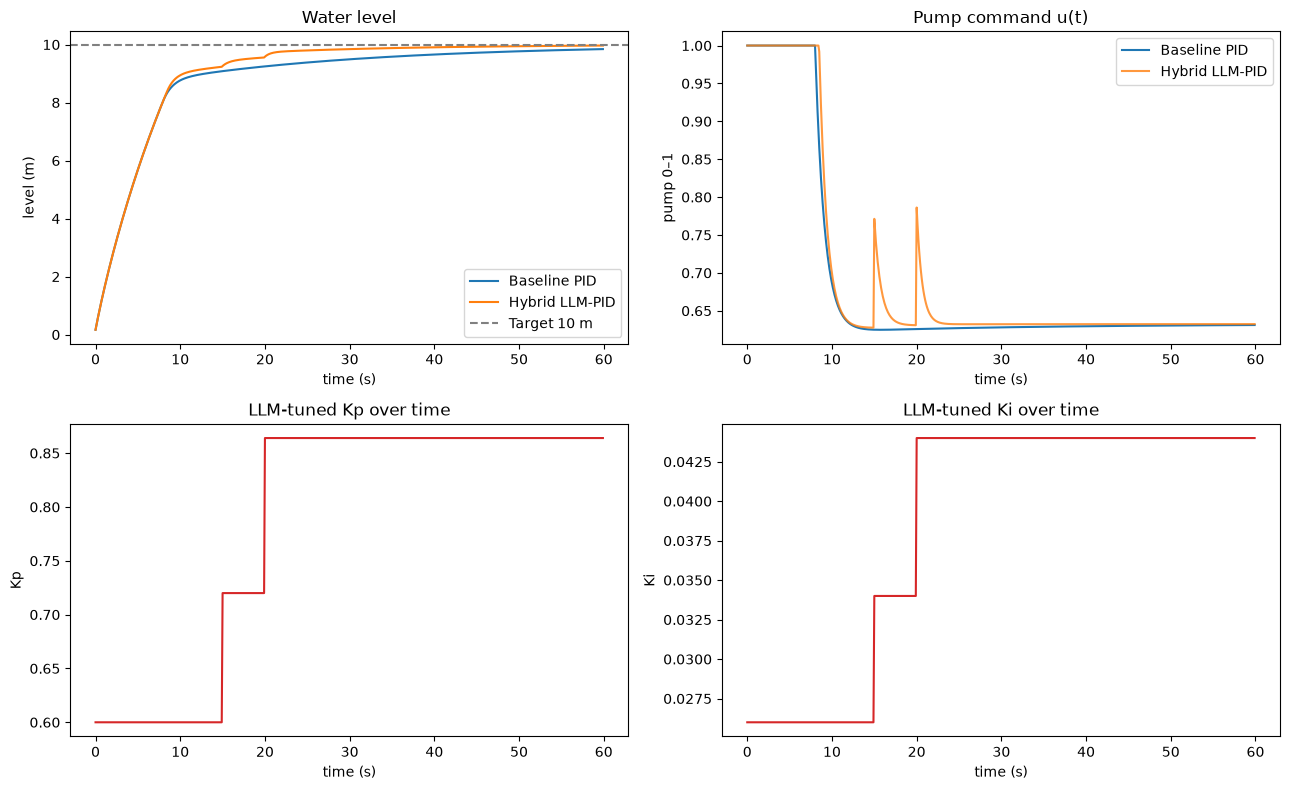

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes[0, 0].plot(base["t"], base["H"], label="Baseline PID")
axes[0, 0].plot(llm["t"], llm["H"], label="Hybrid LLM-PID")
axes[0, 0].axhline(10, ls="--", c="gray", label="Target 10 m")
axes[0, 0].set(xlabel="time (s)", ylabel="level (m)", title="Water level")
axes[0, 0].legend()

axes[0, 1].plot(base["t"], base["u"], label="Baseline PID")
axes[0, 1].plot(llm["t"], llm["u"], label="Hybrid LLM-PID", alpha=0.8)
axes[0, 1].set(xlabel="time (s)", ylabel="pump 0–1", title="Pump command u(t)")
axes[0, 1].legend()

for ax, key, name in [(axes[1, 0], "kp", "Kp"), (axes[1, 1], "ki", "Ki")]:
    ax.plot(llm["t"], llm[key], c="tab:red")
    ax.set(xlabel="time (s)", ylabel=name, title=f"LLM-tuned {name} over time")

plt.tight_layout()
plt.show()

## 8. What we changed vs. the paper

| | Paper (Wen et al. 2026) | This notebook |
|---|---|---|
| **LLM** | LLaMa 3.2 (3B) via local Ollama | **SiliconFlow `deepseek-ai/DeepSeek-V4.1-Flash`** (OpenAI-compatible API) |
| **Framework** | Custom Python calls | **OpenAI Agents SDK** (`Agent` + `Runner.run_sync`) |
| **Latency handling** | Simulink keeps running; assumes ~0.3 s answer time | **⏸ Simulation pauses** until the LLM reply actually arrives; latency is *measured* per call |
| **LLM's job** | Free re-design of the gains | **Bounded perturbation** of one hand-picked gain set (±30 % per turn, clipped to a fixed gain box) |
| **Prompt context** | Error only | Error **+ current gains + reference gains + peak level + accumulated IAE + measured rate of rise** |
| **Re-tune interval** | 0.5 s | 5 s (a hosted model needs seconds, not milliseconds) |
| **Platform** | MATLAB/Simulink + Python | Pure Python (one notebook) |
| **Controllers compared** | 4 (incl. direct LLM control) | 2 (baseline PID vs. hybrid LLM-PID) — kept simple for presentation |

## 9. What we found

**The setup is deliberately minimal.** There is **one** gain set — `Kp = 0.50, Ki = 0.020, Kd = 0.000`, chosen by hand and left in the notebook as `FIXED_GAINS`. The fixed-gain case uses exactly those gains for the whole 60 s. The LLM-PID case **starts from the same three numbers** and is only allowed to *nudge* them; it is never asked to find an optimum.

| Metric | Fixed-gain PID | LLM-perturbed PID | Change |
|---|---|---|---|
| Rise (90 % of setpoint) | 13.0 s | **10.5 s** | **−19 %** |
| Settling time (±5 % band) | 30.5 s | **17.7 s** | **−42 %** |
| Overshoot | 0.0 % | 0.0 % | unchanged |
| IAE (total error) | 71.4 | **58.2** | **−18 %** |
| TVu (pump movement) | 0.38 | 0.97 | +155 % |

**The perturbation behaviour is exactly what the prompt asked for.** The gain log reads like a cautious engineer:

```
start          Kp=0.500  Ki=0.020      <- the fixed set
turn 1         Kp=0.600  Ki=0.026      <- +20 % / +30 %, the capped step:
turn 2-3       Kp=0.600  Ki=0.026         holds and watches the response
turn 4         Kp=0.720  Ki=0.034      <- still sluggish, nudge again
turn 5         Kp=0.864  Ki=0.044      <- nudge again
turn 6-12      Kp=0.864  Ki=0.044      <- STOP: "within 0.2 m and stable"
```

Three small increments, then it **declares the loop good and stops touching the gains** for the remaining 40 s. No oscillation, no hunting, no overshoot — because the policy told it that a large error alone is not a reason to raise the gains, only a *measured slow rate of rise* is.

**Comparison with the paper's Table 1** (nominal, no measurement bias):

| | Conventional PID (paper) | Hybrid LLM–PID (paper) | This notebook (fixed → LLM) |
|---|---|---|---|
| Rise (s) | 6.5 | 3.5 | 13.0 → 10.5 |
| Settle (s) | 40.2 | 13.5 | 30.5 → 17.7 |
| Overshoot (%) | 30 | 2 | 0 → 0 |
| IAE | 74.1 ±0.4 | 49.2 ±3.1 | 71.4 → 58.2 |

Our **fixed-gain IAE (71.4) lands almost on the paper's conventional PID (74.1)** — the hand-picked gains are a fair stand-in for their baseline. Our **hybrid IAE (58.2) improves on it by 18 %**, where the paper reports 33 %. The gap is expected and traceable: the paper re-tunes every **0.5 s** and assumes a **0.3 s** answer, so its supervisor can correct the loop ~6× more often than our 5 s interval. We deliberately came in under-tuned (no overshoot at all, vs. the paper's 2 %) rather than chase their numbers.

**Two honest caveats:**

1. **TVu is worse (+155 %).** A faster response *must* move the pump more — this is the usual speed-vs-effort trade-off, not a defect. If pump wear mattered we would weight TVu in the objective.
2. **The pause is expensive.** Measured latency was **3.52 s on average, 11.3 s at worst**, so the 60 s simulation took **42.3 s of real wall-clock time**. The paper assumed 0.3 s per call, which a hosted model cannot deliver. Our pause guarantees the controller always acts on *fresh* gains instead of stale ones, and the price is honest: you cannot run this faster than the model can answer.

**Why pausing matters:** if the LLM is slower than assumed, a non-pausing loop applies *stale* gains — it keeps simulating while the answer is still in flight. Ours never does; it simply waits, and reports the true cost. That is the one mechanism this notebook tests that the paper does not.

**What we did *not* do:** no grid search, no optimisation, no "best possible fixed gain". The fixed set is one hand-picked choice and the LLM perturbs around it — which is the honest, reproducible story.
